# Módulo 401b - Introducción al espacio lineal

> Diplomado en Python y Ciecia de Datos (Generación 2)
>
> Instituto Politécnico Nacional
>
> Centro de Investigación en Cómputo
>
> Departamento de Diplomados y Extensión Profesional

> Alan Badillo Salas
>
> Jueves 19, noviembre 2026.

## Contenido

1. Características continuas
2. Características discretas
3. Espacio lineal ($z = \beta_0 + \beta_1 \cdot x_1 + \beta_2 \cdot x_2 + \ldots + \beta_k \cdot x_k$)

In [3]:
# ! python -m pip install numpy pandas matplotlib seaborn

In [1]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [4]:
iris = pandas.read_csv("../conjuntos/iris.csv")

iris

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


![iris ref1](../conjuntos/iris_ref1.webp)

![iris ref2](../conjuntos/iris_ref2.jpeg)

In [5]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   variety       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [7]:
iris.describe() # Describe estadísticamente las columnas numéricas

,sepal.length,sepal.width,petal.length,petal.width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [8]:
c1 = iris["sepal.length"] # numérica | continua
c2 = iris["sepal.width"] # numérica | continua
c3 = iris["petal.length"] # numérica | continua
c4 = iris["petal.width"] # numérica | continua
c5 = iris["variety"] # texto/categórica | discreta

## 1. Características continuas

In [10]:
c1 # sepal.length

0      5.1
1      4.9
2      4.7
3      4.6
4      5.0
      ... 
145    6.7
146    6.3
147    6.5
148    6.2
149    5.9
Name: sepal.length, Length: 150, dtype: float64

<Axes: ylabel='Density'>

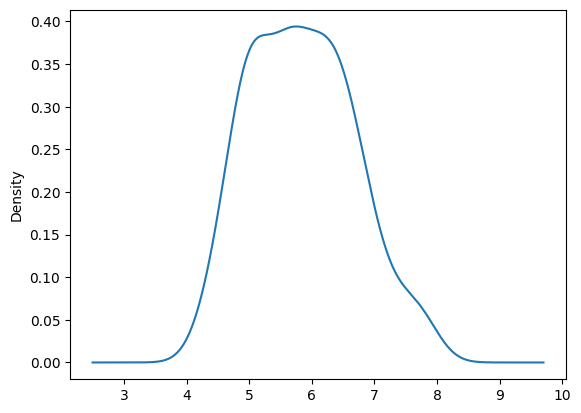

In [ ]:
c1.plot.density() # Dónde se ubican los valores del largo del sépalo en todas las observaciones

<Axes: xlabel='sepal.length', ylabel='Density'>

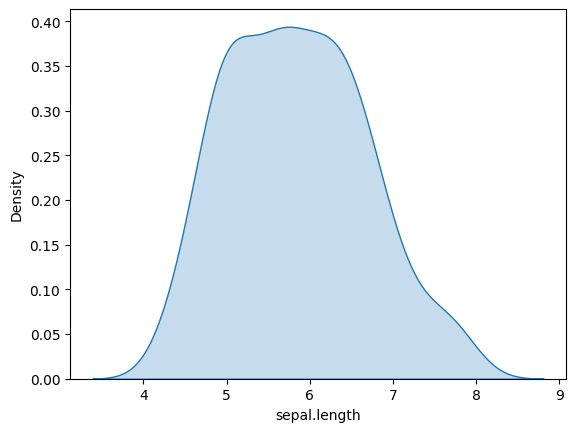

In [21]:
seaborn.kdeplot(x=c1, fill=True) # Densidad estimada (Kernel Density Estimation / Estimación gaussiana)

<Axes: xlabel='sepal.length', ylabel='Density'>

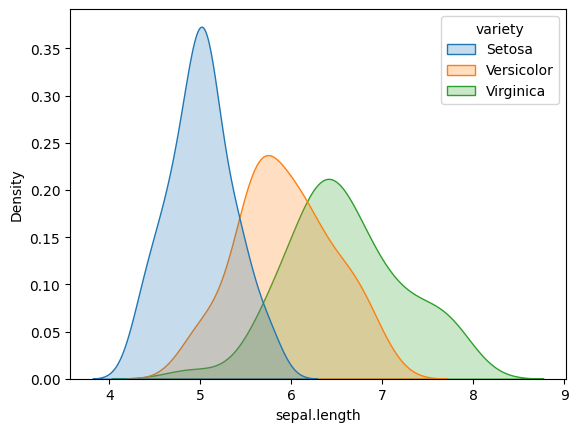

In [ ]:
seaborn.kdeplot(x=c1, hue=c5, fill=True) # El largo de sépalo segmentado por variedad

<Axes: xlabel='sepal.length'>

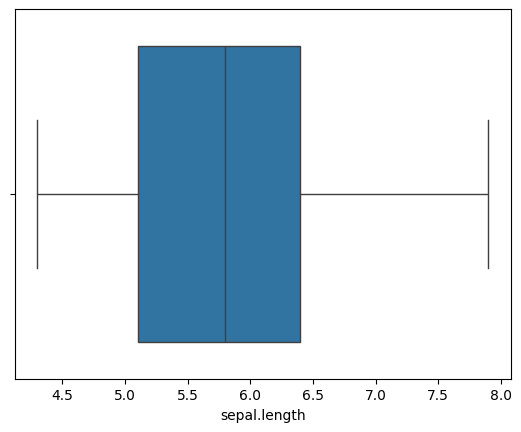

In [17]:
seaborn.boxplot(x=c1)

<Axes: xlabel='sepal.length', ylabel='variety'>

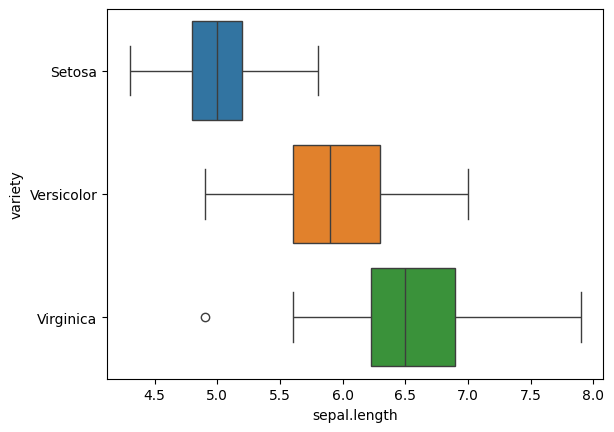

In [20]:
seaborn.boxplot(x=c1, y=c5, hue=c5) # Dónde viven los largos de sépalo en cada variedad

<Axes: xlabel='sepal.length', ylabel='variety'>

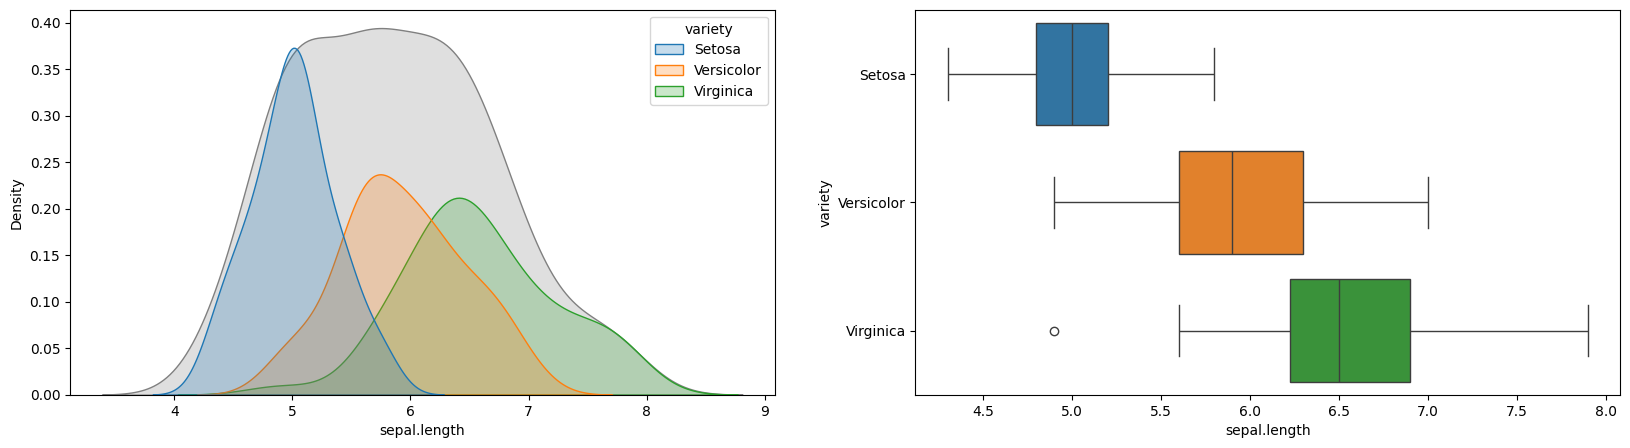

In [ ]:
figure, axis = pyplot.subplots(1, 2, figsize=(20, 5))

seaborn.kdeplot(x=c1, color="gray", fill=True, ax=axis[0])
seaborn.kdeplot(x=c1, hue=c5, fill=True, ax=axis[0])

seaborn.boxplot(x=c1, y=c5, hue=c5)

<Axes: xlabel='sepal.width', ylabel='variety'>

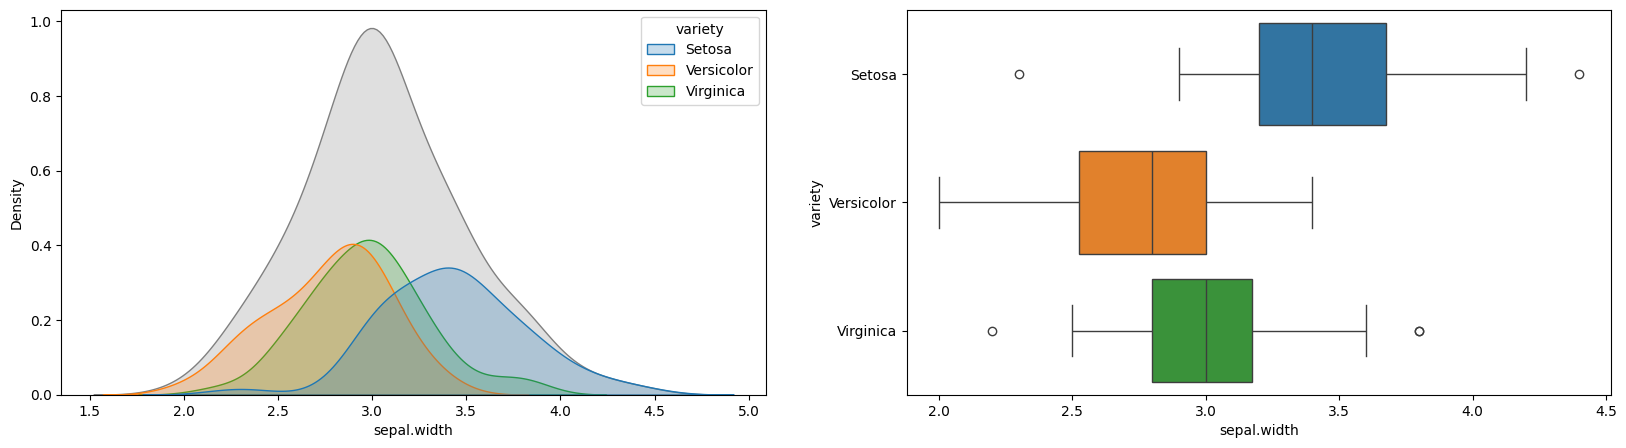

In [33]:
figure, axis = pyplot.subplots(1, 2, figsize=(20, 5))

seaborn.kdeplot(x=c2, color="gray", fill=True, ax=axis[0])
seaborn.kdeplot(x=c2, hue=c5, fill=True, ax=axis[0])

seaborn.boxplot(x=c2, y=c5, hue=c5)

<Axes: xlabel='petal.length', ylabel='variety'>

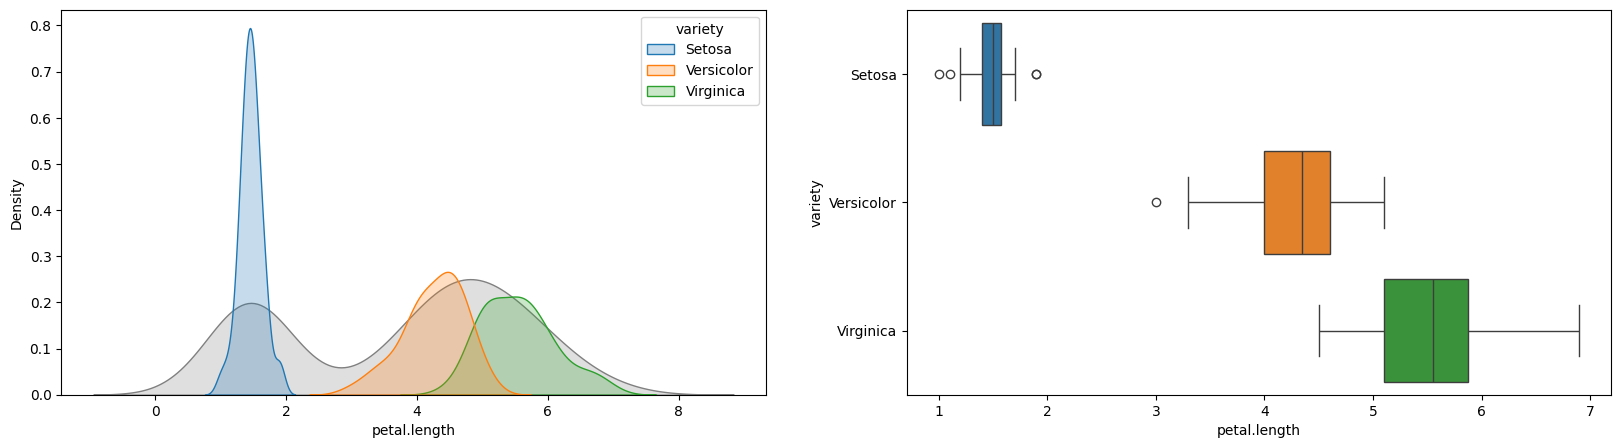

In [34]:
figure, axis = pyplot.subplots(1, 2, figsize=(20, 5))

seaborn.kdeplot(x=c3, color="gray", fill=True, ax=axis[0])
seaborn.kdeplot(x=c3, hue=c5, fill=True, ax=axis[0])

seaborn.boxplot(x=c3, y=c5, hue=c5)

<Axes: xlabel='petal.width', ylabel='variety'>

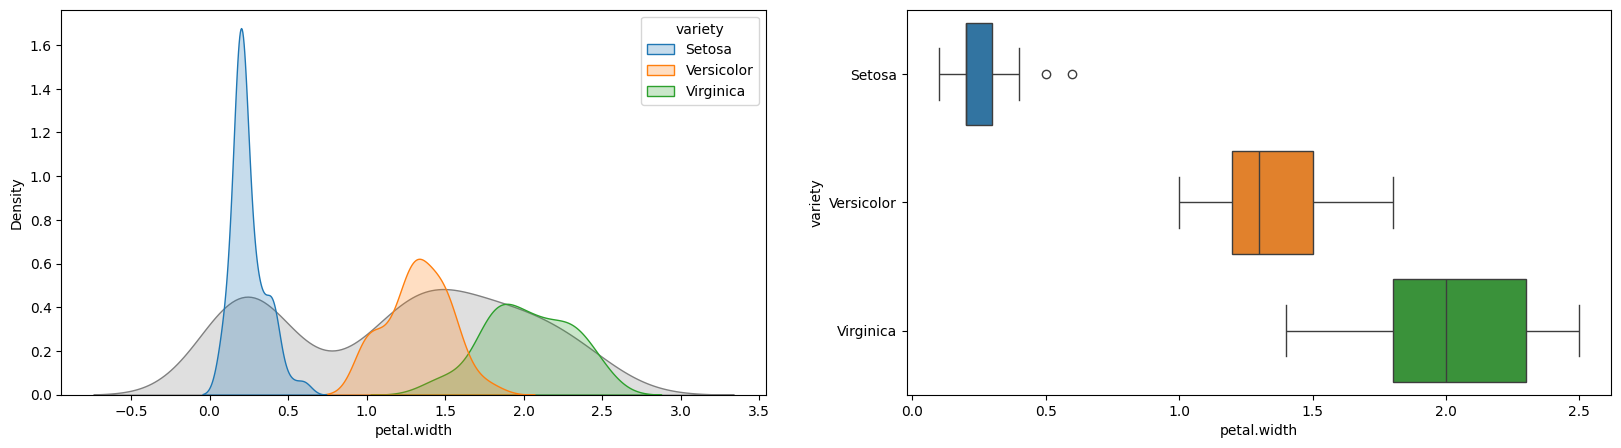

In [35]:
figure, axis = pyplot.subplots(1, 2, figsize=(20, 5))

seaborn.kdeplot(x=c4, color="gray", fill=True, ax=axis[0])
seaborn.kdeplot(x=c4, hue=c5, fill=True, ax=axis[0])

seaborn.boxplot(x=c4, y=c5, hue=c5)

## 2. Características discretas

In [36]:
c5

0         Setosa
1         Setosa
2         Setosa
3         Setosa
4         Setosa
         ...    
145    Virginica
146    Virginica
147    Virginica
148    Virginica
149    Virginica
Name: variety, Length: 150, dtype: object

In [38]:
# Variable discreta -> 3 clases (categorías)
c5.value_counts() # Soporte (cantidad de observaciones de cada clase)

variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

In [39]:
c5.value_counts(normalize=True)

variety
Setosa        0.333333
Versicolor    0.333333
Virginica     0.333333
Name: proportion, dtype: float64

<Axes: ylabel='variety'>

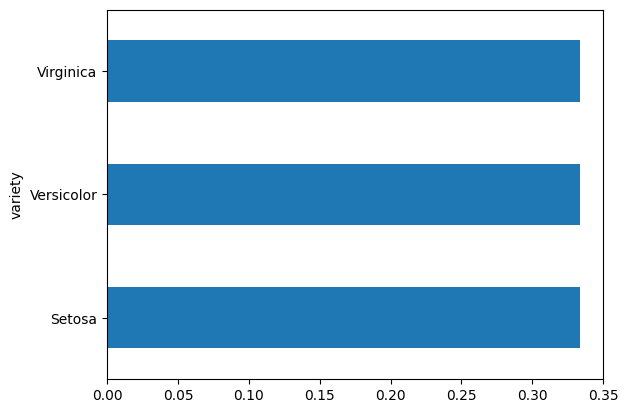

In [40]:
c5.value_counts(normalize=True).plot.barh()

### Transformación o codificación del espacio discreto al espacio continuo

* **Transformación directa** - Cada clase absorbe un valor natural, por ejemplo, si las clases son nivel educativo: primaria=1, secundaria=2, preparatoria=3, universidad=4, posgrado=5
* **Transformación lógica** - Cada clase absorbe un valor lógico supuesto, por ejemplo, si las clases son sexo: hombre=-1, mujer=1, o por ejemplo, si las clases son tipo de material: cemento=costo promedio del cemento, acero=costo promedio del acero, madera=costo promedio de la madera
* **Expansión del espacio** - Cada clase se expande en *dummies* donde cada *dummy* responde 1 si pertenece a la clase o 0 si no pertenece, esto expande una variable de 3-clases en 3-variables binarias (conocida como codificación *One-Hot*)

In [45]:
c5_setosa = (c5 == "Setosa").astype(int) # Pertenece a la clase Setosa
c5_setosa.name = "variety_setosa"
c5_versicolor = (c5 == "Versicolor").astype(int) # Pertenece a la clase versicolor
c5_versicolor.name = "variety_versicolor"
c5_virginica = (c5 == "Virginica").astype(int) # Pertenece a la clase virgínica
c5_virginica.name = "variety_virginica"

pandas.DataFrame([c5, c5_setosa, c5_versicolor, c5_virginica]).T

,variety,variety_setosa,variety_versicolor,variety_virginica
0,Setosa,1,0,0
1,Setosa,1,0,0
2,Setosa,1,0,0
3,Setosa,1,0,0
4,Setosa,1,0,0
...,...,...,...,...
145,Virginica,0,0,1
146,Virginica,0,0,1
147,Virginica,0,0,1
148,Virginica,0,0,1


<Axes: xlabel='sepal.length', ylabel='variety_setosa'>

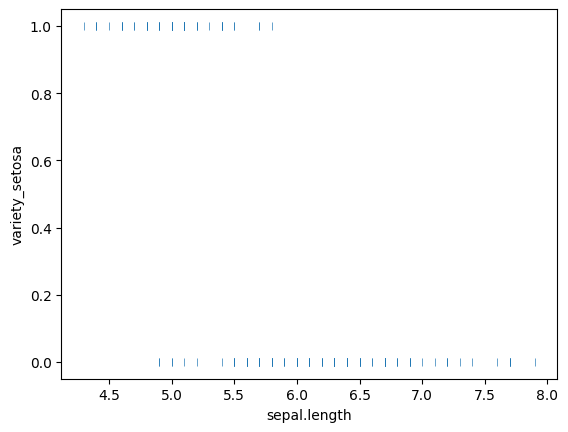

In [47]:
seaborn.scatterplot(x=c1, y=c5_setosa, marker="|")

<Axes: xlabel='sepal.length', ylabel='variety_setosa'>

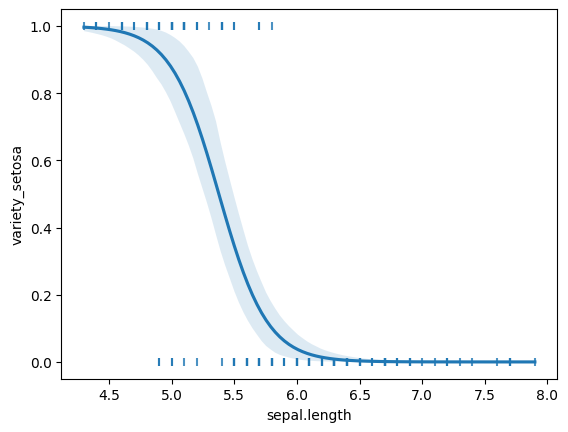

In [51]:
seaborn.regplot(x=c1, y=c5_setosa, logistic=True, marker="|")

<Axes: xlabel='sepal.width', ylabel='variety_setosa'>

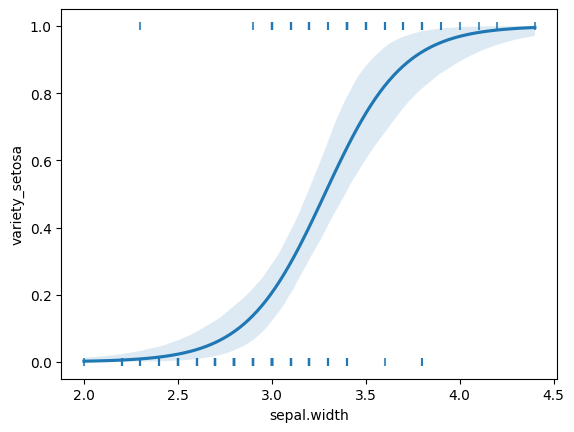

In [52]:
seaborn.regplot(x=c2, y=c5_setosa, logistic=True, marker="|")

<Axes: xlabel='petal.length', ylabel='variety_versicolor'>

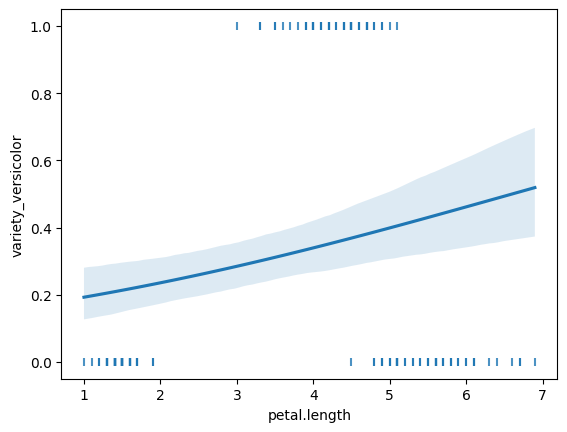

In [53]:
seaborn.regplot(x=c3, y=c5_versicolor, logistic=True, marker="|")

<Axes: xlabel='petal.length', ylabel='variety_versicolor'>

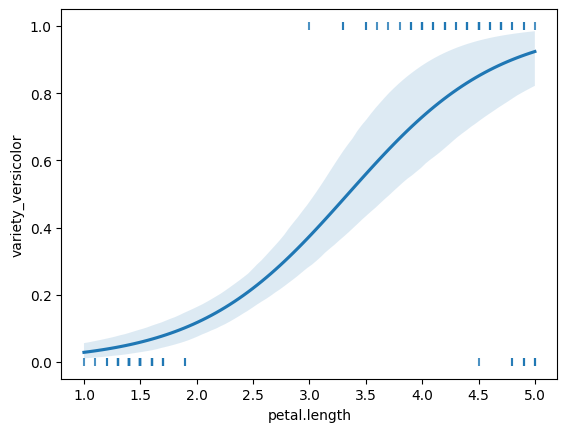

In [55]:
mascara1 = c3 <= 5
seaborn.regplot(x=c3[mascara1], y=c5_versicolor[mascara1], logistic=True, marker="|")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/genmod/families/links.py:198: RuntimeWarning: overflow encountered in exp
  t = np.exp(-z)


<Axes: xlabel='petal.length', ylabel='variety_versicolor'>

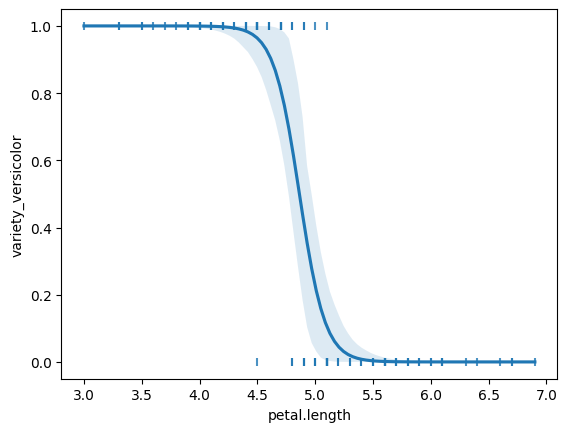

In [59]:
mascara2 = c3 >= 2.5
seaborn.regplot(x=c3[mascara2], y=c5_versicolor[mascara2], logistic=True, marker="|")

## 3. Espacio lineal 

$$
z = \beta_0 + \beta_1 \cdot x_1 + \beta_2 \cdot x_2 + \ldots + \beta_k \cdot x_k
$$

<Axes: xlabel='None', ylabel='Density'>

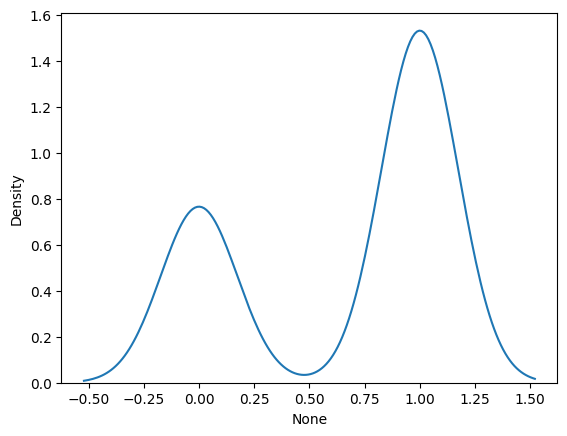

In [72]:
b0 = 2 # bias
b1 = 1.2 # factor c1
b2 = 0.6 # factor c2
b3 = -0.5 # factor c3
b4 = 0.9 # factor c4

z = b0 + b1 * c1 + b2 * c2 + b3 * c3 + b4 * c4

y = c5_setosa

yp = numpy.exp(z) / (1 + numpy.exp(z))

e = y - yp

l = (e ** 2)

seaborn.kdeplot(x=l)